# Demo of DBSCAN clustering algorithm: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cluster/plot_dbscan.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/cluster/plot_dbscan.html)).

**Scenario:** 750 blobs (`random_state=0`), `StandardScaler`, `DBSCAN(eps=0.3, min_samples=10)`;
cluster/noise counts, clustering metrics and the core/border/noise plot. Beyond the example: the
`dbscan` function, `metric="precomputed"`, `metric="manhattan"`, Minkowski `p=3`, `sample_weight`,
Float32, `clone` + `set_params` refit, and cluster estimators used as transformers inside
`moxie.pipeline` (FeatureAgglomeration, Birch, MiniBatchKMeans, KMeans).

**Adaptations:**
- `make_blobs` runs in Python (Moxie has no `datasets`); the raw data are shared and Moxie's
  `StandardScaler` scales them.
- The metrics (homogeneity, ..., silhouette) are computed in Python from each implementation's
  labels; Moxie has no `metrics` module yet.

**Determinism:** DBSCAN is deterministic: labels, core samples and components are compared exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cluster/plot_dbscan")

## 1. scikit-learn (Python reference)

In [2]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X_raw, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

X = StandardScaler().fit_transform(X_raw)

import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)


def scores(labels):
    return [metrics.homogeneity_score(labels_true, labels), metrics.completeness_score(labels_true, labels),
            metrics.v_measure_score(labels_true, labels), metrics.adjusted_rand_score(labels_true, labels),
            metrics.adjusted_mutual_info_score(labels_true, labels), metrics.silhouette_score(X, labels)]


print("Homogeneity: %.3f\nCompleteness: %.3f\nV-measure: %.3f\nAdjusted Rand Index: %.3f\n"
      "Adjusted Mutual Information: %.3f\nSilhouette Coefficient: %.3f" % tuple(scores(labels)))

Estimated number of clusters: 3
Estimated number of noise points: 18
Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


In [3]:
# Beyond the example
from scipy.spatial.distance import cdist
from sklearn.base import clone
from sklearn.cluster import dbscan

D = cdist(X, X)
sk_fn_core, sk_fn_labels = dbscan(X, eps=0.3, min_samples=10)
sk_pre = DBSCAN(eps=0.3, min_samples=10, metric="precomputed").fit(D)
sk_man = DBSCAN(eps=0.4, min_samples=8, metric="manhattan").fit(X)
sk_mink = DBSCAN(eps=0.3, min_samples=10, metric="minkowski", p=3).fit(X)
w = np.random.RandomState(0).uniform(0.2, 2.0, len(X))
sk_w = DBSCAN(eps=0.3, min_samples=10).fit(X, sample_weight=w)
sk_32 = DBSCAN(eps=0.3, min_samples=10).fit(X.astype(np.float32))
sk_clone = clone(db).set_params(eps=0.2, min_samples=5).fit(X)
nb.share(X_raw=X_raw, D=D, w=w)

## 2. Moxie (native Mojo)

In [4]:
%%mojo dbscan
from moxie.base import clone
from moxie.cluster import DBSCAN, dbscan
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save


def main() raises:
    var scaler = StandardScaler()
    var X = scaler.fit_transform(load("X_raw"))
    save("X", X)
    var db = DBSCAN(0.3, min_samples=10)
    _ = db.fit(X)
    save("labels", db.labels_); save("core", db.core_sample_indices_); save("components", db.components_)
    var res = dbscan(X, 0.3, min_samples=10)
    save("fn_core", res.core_sample_indices); save("fn_labels", res.labels)
    var pre = DBSCAN(0.3, min_samples=10, metric="precomputed")
    _ = pre.fit(load("D"))
    save("pre_labels", pre.labels_); save("pre_core", pre.core_sample_indices_)
    var man = DBSCAN(0.4, min_samples=8, metric="manhattan")
    save("man_labels", man.fit_predict(X))
    var mink = DBSCAN(0.3, min_samples=10, metric="minkowski", p=Optional[Float64](3.0))
    save("mink_labels", mink.fit_predict(X))
    var weighted = DBSCAN(0.3, min_samples=10)
    _ = weighted.fit(X, sample_weight=load("w"))
    save("w_labels", weighted.labels_); save("w_core", weighted.core_sample_indices_)
    var db32 = DBSCAN[DType.float32](0.3, min_samples=10)
    _ = db32.fit(X.astype[DType.float32]())
    save("f32_labels", db32.labels_)
    var cl = clone(db)
    _ = cl.set_params(eps=0.2, min_samples=5)
    _ = cl.fit(X)
    save("clone_labels", cl.labels_)

## 3. Side by side and parity

,impl,homo,compl,v-meas,ARI,AMI,silhouette
0,sklearn,0.953,0.883,0.917,0.952,0.916,0.626
1,moxie,0.953,0.883,0.917,0.952,0.916,0.626


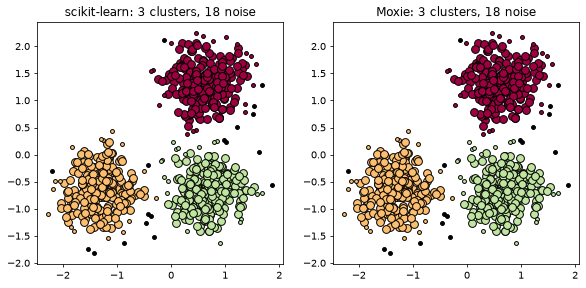

True

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

mx = nb.results["dbscan"]
display(pd.DataFrame([["sklearn", *scores(labels)], ["moxie", *scores(mx["labels"])]],
                     columns=["impl", "homo", "compl", "v-meas", "ARI", "AMI", "silhouette"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=70)
for ax, lab, core, title in ((axes[0], labels, db.core_sample_indices_, "scikit-learn"),
                             (axes[1], mx["labels"], mx["core"], "Moxie")):
    unique_labels = set(lab)
    core_samples_mask = np.zeros_like(lab, dtype=bool)
    core_samples_mask[core] = True
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_member_mask = lab == k
        xy = X[class_member_mask & core_samples_mask]
        ax.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=8)
        xy = X[class_member_mask & ~core_samples_mask]
        ax.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=4)
    n = len(set(lab)) - (1 if -1 in lab else 0)
    ax.set_title(f"{title}: {n} clusters, {list(lab).count(-1)} noise")
plt.show()

nb.compare("StandardScaler output", X, mx["X"], rtol=1e-12, atol=1e-14,
           reason="mean/std reductions in a different order")
nb.compare("labels_", labels, mx["labels"], exact=True)
nb.compare("core_sample_indices_", db.core_sample_indices_, mx["core"], exact=True)
nb.compare("components_", db.components_, mx["components"], rtol=1e-12, atol=1e-14,
           reason="rows of the scaled data, which differ only by scaler roundoff")
nb.compare("dbscan() core_sample_indices", sk_fn_core, mx["fn_core"], exact=True)
nb.compare("dbscan() labels", sk_fn_labels, mx["fn_labels"], exact=True)
nb.compare("metric='precomputed' labels_", sk_pre.labels_, mx["pre_labels"], exact=True)
nb.compare("metric='precomputed' core_sample_indices_", sk_pre.core_sample_indices_, mx["pre_core"], exact=True)
nb.compare("metric='manhattan' fit_predict", sk_man.labels_, mx["man_labels"], exact=True)
nb.compare("minkowski p=3 fit_predict", sk_mink.labels_, mx["mink_labels"], exact=True)
nb.compare("sample_weight labels_", sk_w.labels_, mx["w_labels"], exact=True)
nb.compare("sample_weight core_sample_indices_", sk_w.core_sample_indices_, mx["w_core"], exact=True)
nb.compare("Float32 labels_", sk_32.labels_, mx["f32_labels"], exact=True)
nb.compare("clone + set_params(eps=0.2, min_samples=5) refit labels_", sk_clone.labels_, mx["clone_labels"], exact=True)

### Composition: cluster estimators as pipeline transformers

Beyond the example. In sklearn, `FeatureAgglomeration`, `Birch`, `MiniBatchKMeans` and `KMeans`
are `TransformerMixin`s and can feed a supervised final step or a `FeatureUnion`. Here they run
on the scaled blobs with a `Ridge` regressor predicting the blob index.

In [6]:
from sklearn.cluster import Birch, FeatureAgglomeration, KMeans, MiniBatchKMeans
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline, make_union

X4 = np.c_[X, X[:, :1] * X[:, 1:], X[:, :1] - X[:, 1:]]
y = labels_true.astype(np.float64)
sk_fa = make_pipeline(FeatureAgglomeration(n_clusters=2), Ridge()).fit(X4, y).predict(X4)
sk_birch = make_pipeline(Birch(n_clusters=3), Ridge()).fit(X4, y).predict(X4)
sk_mbk = make_pipeline(MiniBatchKMeans(3, random_state=0, n_init=1, batch_size=100), Ridge()).fit(X4, y).predict(X4)
sk_union = make_union(KMeans(3, random_state=0, n_init=1), FeatureAgglomeration(n_clusters=2)).fit_transform(X4)
sk_clone_pipe = clone(make_pipeline(FeatureAgglomeration(n_clusters=3), Ridge())).fit(X4, y).predict(X4)
nb.share(X4=X4, y=y)

In [7]:
%%mojo cluster_pipelines
from moxie.base import clone
from moxie.cluster import Birch, FeatureAgglomeration, KMeans, MiniBatchKMeans
from moxie.linear_model import Ridge
from moxie.pipeline import make_pipeline, make_union
from moxie_nb_io import load, save


def main() raises:
    var X4 = load("X4")
    var y = load("y")
    var fa = make_pipeline(FeatureAgglomeration(n_clusters=2), Ridge())
    _ = fa.fit(X4, y)
    save("fa", fa.predict(X4))
    var birch = make_pipeline(Birch(n_clusters=Optional[Int](3)), Ridge())
    _ = birch.fit(X4, y)
    save("birch", birch.predict(X4))
    var mbk = make_pipeline(MiniBatchKMeans(3, random_state=0, n_init=1, batch_size=100), Ridge())
    _ = mbk.fit(X4, y)
    save("mbk", mbk.predict(X4))
    var union = make_union(KMeans(3, random_state=0, n_init=1), FeatureAgglomeration(n_clusters=2))
    save("union", union.fit_transform(X4))
    var cl = clone(make_pipeline(FeatureAgglomeration(n_clusters=3), Ridge()))
    _ = cl.fit(X4, y)
    save("clone_pipe", cl.predict(X4))

In [8]:
mp = nb.results["cluster_pipelines"]
pipe_reason = "Float64 pooling/CF/centroid sums then a Ridge solve; summation order differs"
nb.compare("make_pipeline(FeatureAgglomeration, Ridge).predict", sk_fa, mp["fa"], rtol=1e-10, atol=1e-12, reason=pipe_reason)
nb.compare("make_pipeline(Birch, Ridge).predict", sk_birch, mp["birch"], rtol=1e-10, atol=1e-12, reason=pipe_reason)
nb.compare("make_pipeline(MiniBatchKMeans, Ridge).predict", sk_mbk, mp["mbk"], rtol=1e-10, atol=1e-12, reason=pipe_reason)
nb.compare("make_union(KMeans, FeatureAgglomeration).fit_transform", sk_union, mp["union"], rtol=1e-10, atol=1e-12, reason=pipe_reason)
nb.compare("clone(make_pipeline(FeatureAgglomeration, Ridge)).fit.predict", sk_clone_pipe, mp["clone_pipe"], rtol=1e-10, atol=1e-12, reason=pipe_reason)

True

### A clusterer cannot end a Moxie Pipeline

`make_pipeline(StandardScaler(), DBSCAN(...)).fit_predict(X)` is a common sklearn idiom. Moxie's
`make_pipeline` requires a supervised predictor as its final step, so it does not compile.

In [9]:
%%mojo dbscan_pipeline --expect-fail
from moxie.cluster import DBSCAN
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load


def main() raises:
    var pipe = make_pipeline(StandardScaler(), DBSCAN(0.3, min_samples=10))
    _ = pipe.fit_predict(load("X_raw"))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_dbscan/dbscan_pipeline.mojo:8:54: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'DBSCAN' to 'E', argument type 'DBSCAN' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(StandardScaler(), DBSCAN(0.3, min_samples=10))
               ~~~~~~~~~~~~~                   ~~~~~~^~~~~~~~~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_dbscan/dbscan_pipeline.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39:5: note: function declared here
def make_pipeline[P: TransformerMixin & Deinitable, E: SupervisedEstimator & Pr

In [10]:
nb.note("make_pipeline(StandardScaler(), DBSCAN)", "GAP",
        "Moxie Pipeline needs a SupervisedEstimator & Predictor final step; clusterers cannot end a "
        "pipeline (#21 part 1). Scaled by hand above.")
nb.note("sklearn.metrics clustering scores", "ADAPTED",
        "no moxie.metrics yet; scores computed in Python from both implementations' labels")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
StandardScaler output,PASS,"(750, 2)","(750, 2)",0,0,"rtol=1e-12, atol=1e-14",,mean/std reductions in a different order
labels_,PASS,"(750,)","(750,)",,,exact,0 mismatches,
core_sample_indices_,PASS,"(679,)","(679,)",,,exact,0 mismatches,
components_,PASS,"(679, 2)","(679, 2)",0,0,"rtol=1e-12, atol=1e-14",,"rows of the scaled data, which differ only by scaler roundoff"
dbscan() core_sample_indices,PASS,"(679,)","(679,)",,,exact,0 mismatches,
dbscan() labels,PASS,"(750,)","(750,)",,,exact,0 mismatches,
metric='precomputed' labels_,PASS,"(750,)","(750,)",,,exact,0 mismatches,
metric='precomputed' core_sample_indices_,PASS,"(679,)","(679,)",,,exact,0 mismatches,
metric='manhattan' fit_predict,PASS,"(750,)","(750,)",,,exact,0 mismatches,
minkowski p=3 fit_predict,PASS,"(750,)","(750,)",,,exact,0 mismatches,
